In [1]:
from pathlib import Path
import pickle

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

#Dataset Directory
DATA_DIR = Path("data/us")

#Load existing SmartSense partitions
with open(DATA_DIR / "trn_instance_10.pkl", "rb") as f:
    train = pickle.load(f)

with open(DATA_DIR / "vld_instance_10.pkl", "rb") as f:
    val = pickle.load(f)

with open(DATA_DIR / "test_instance_10.pkl", "rb") as f:
    test = pickle.load(f)

#Inspect dataset structure
print("Training shape:", train.shape)
print("Validation shape:", val.shape)
print("Test shape:", test.shape)

print("\nTraining data type:", train.dtype)
print("Events per sequence:", train.shape[1])
print("Features per event:", train.shape[2])

#Confirm expected structure
for name, data in [
    ("Training", train),
    ("Validation", val),
    ("Test", test)
]:
    assert data.ndim == 3, f"{name} must be 3D"
    assert data.shape[1:] == (10,5), (
        f"Unexpected shape for {name}: {data.shape}"
    )

print("\nAll dataset structure checks passed")

Training shape: (47516, 10, 5)
Validation shape: (6789, 10, 5)
Test shape: (13577, 10, 5)

Training data type: int64
Events per sequence: 10
Features per event: 5

All dataset structure checks passed


In [2]:
#First 9 events are the input sequence
X_train = train[:, :9, :]
X_val = val[:, :9, :]
X_test = test[:, :9, :]

#Device-control ID of the 10th event is the target
y_train = train[:, 9, 4]
y_val = val[:, 9, 4]
y_test = test[:, 9, 4]

#Inspect shapes
print("Input shapes:")
print("X_train:", X_train.shape)
print("X_val:", X_val.shape)
print("X_test:", X_test.shape)

print("\nTarget shapes:")
print("y_train:", y_train.shape)
print("y_val:", y_val.shape)
print("y_test", y_test.shape)

#Inspect number of unique action classes
train_classes = np.unique(y_train)
val_classes = np.unique(y_val)
test_classes = np.unique(y_test)

print("\nUnique target classes:")
print("Training:", len(train_classes))
print("Validation:", len(val_classes))
print("Test:", len(test_classes))

#Check whether validation/test contain unseen classes
unseen_val = np.setdiff1d(val_classes, train_classes)
unseen_test = np.setdiff1d(test_classes, train_classes)

print("\nClasses not observed during training:")
print("Validation:", unseen_val)
print("Test:", unseen_test)

#Confirm no target event is included in X
assert X_train.shape[1] == 9
assert X_val.shape[1] == 9
assert X_test.shape[1] == 9

print("\nClassification task setup complete")

Input shapes:
X_train: (47516, 9, 5)
X_val: (6789, 9, 5)
X_test: (13577, 9, 5)

Target shapes:
y_train: (47516,)
y_val: (6789,)
y_test (13577,)

Unique target classes:
Training: 123
Validation: 91
Test: 105

Classes not observed during training:
Validation: [ 20 124 166]
Test: [ 73 136 158 160 166]

Classification task setup complete


Number of training classes: 123

Top 10 most frequent actions:


,Action ID,Count,Percentage
0,245,8995,18.930466
1,107,7582,15.956730
2,246,6345,13.353397
3,236,6240,13.132419
4,108,6043,12.717821
5,102,1423,2.994781
6,133,781,1.643657
7,248,619,1.302719
8,240,602,1.266942
9,209,509,1.071218



Class frequency statistics:


count     123.000000
mean      386.308943
std      1406.775613
min         1.000000
25%         4.000000
50%        21.000000
75%       146.500000
max      8995.000000
Name: count, dtype: float64


Top 10 class share: 82.37%
Classes with fewer than 10 examples: 44


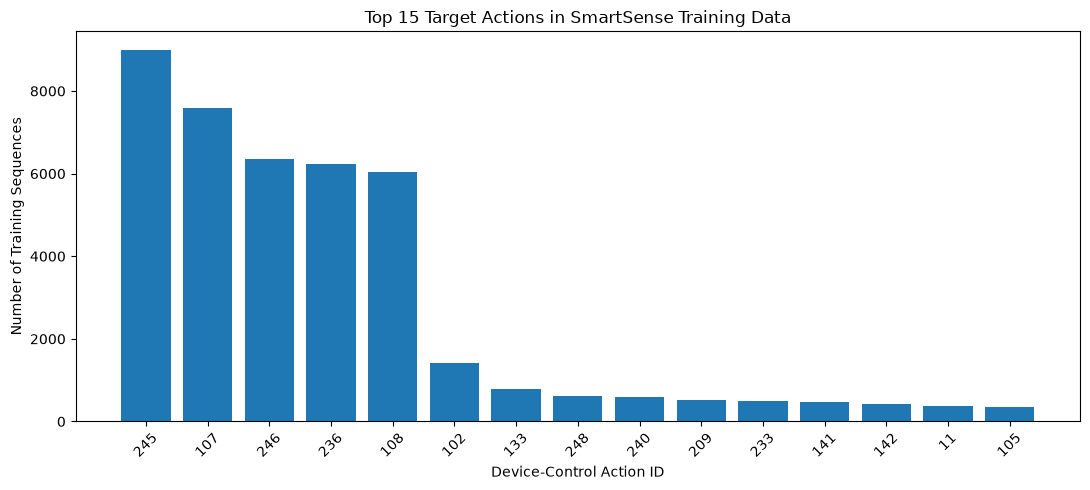

Validation unseen-class examples: 3 / 6789 (0.044%)
Test unseen-class examples: 6 / 13577 (0.044%)


In [3]:
#Count occurrences of each target action
class_counts = pd.Series(y_train).value_counts()

#Create a summary table
class_distribution = pd.DataFrame({
    "Action ID": class_counts.index,
    "Count": class_counts.values
})

class_distribution["Percentage"] = (
    class_distribution["Count"] / len(y_train) * 100
)

print("Number of training classes:", len(class_counts))

print("\nTop 10 most frequent actions:")
display(class_distribution.head(10))

print("\nClass frequency statistics:")
display(class_counts.describe())

#Percentage represented by the 10 most common actions
top_10_share = (
    class_counts.head(10).sum() / len(y_train) * 100
)

#Classes with very few examples
rare_classes = (class_counts < 10).sum()

print(f"\nTop 10 class share: {top_10_share:.2f}%")
print(f"Classes with fewer than 10 examples: {rare_classes}")

#Plot the most common classes
plt.figure(figsize=(11,5))

plt.bar(
    class_distribution.head(15)["Action ID"].astype(str),
    class_distribution.head(15)["Count"]
)

plt.title("Top 15 Target Actions in SmartSense Training Data")
plt.xlabel("Device-Control Action ID")
plt.ylabel("Number of Training Sequences")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

#Measure unseen-class frequency in validation and test
for name, labels in [
    ("Validation", y_val),
    ("Test", y_test)
]:
    unseen_mask = ~np.isin(labels, train_classes)

    print(
        f"{name} unseen-class examples: "
        f"{unseen_mask.sum()} / {len(labels)} "
        f"({unseen_mask.mean() * 100:.3f}%)"
    )

In [4]:
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report
)

# Baseline 1: Most frequent training action
most_frequent_action = pd.Series(y_train).mode()[0]

pred_majority = np.full(
    shape=len(y_val),
    fill_value=most_frequent_action
)

# Baseline 2: Repeat the ninth event's action
pred_repeat = X_val[:, -1, 4].copy()

# Evaluate both baselines
baseline_predictions = {
    "Most Frequent Action": pred_majority,
    "Repeat Last Action": pred_repeat
}

baseline_results = []

for name, predictions in baseline_predictions.items():

    accuracy = accuracy_score(y_val, predictions)

    macro_f1 = f1_score(
        y_val,
        predictions,
        average="macro",
        zero_division=0
    )

    weighted_f1 = f1_score(
        y_val,
        predictions,
        average="weighted",
        zero_division=0
    )

    # Evaluate only actions that differ from the previous one
    non_repeat_mask = (
        y_val != X_val[:, -1, 4]
    )

    non_repeat_accuracy = accuracy_score(
        y_val[non_repeat_mask],
        predictions[non_repeat_mask]
    ) if non_repeat_mask.any() else np.nan

    baseline_results.append({
        "Model": name,
        "Accuracy (%)": accuracy * 100,
        "Macro F1": macro_f1,
        "Weighted F1": weighted_f1,
        "Non-Repeat Accuracy (%)": (
            non_repeat_accuracy * 100
        )
    })

baseline_df = pd.DataFrame(baseline_results)

print("Most frequent training action:", most_frequent_action)

print(
    "Validation actions differing from previous action:",
    int(non_repeat_mask.sum())
)

print("\nBaseline classification results:")
display(baseline_df.round(4))


Most frequent training action: 245
Validation actions differing from previous action: 4782

Baseline classification results:


,Model,Accuracy (%),Macro F1,Weighted F1,Non-Repeat Accuracy (%)
0,Most Frequent Action,18.8982,0.0035,0.0601,15.0983
1,Repeat Last Action,29.5625,0.1580,0.2947,0.0000


In [5]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score
import time

# Flatten the 9-event history into 45 categorical features
X_train_flat = X_train.reshape(len(X_train), -1)
X_val_flat = X_val.reshape(len(X_val), -1)

print("Flattened training shape:", X_train_flat.shape)
print("Flattened validation shape:", X_val_flat.shape)

# Fit the encoder using training data only
encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=True
)

X_train_encoded = encoder.fit_transform(X_train_flat)
X_val_encoded = encoder.transform(X_val_flat)

print("\nEncoded training shape:", X_train_encoded.shape)
print("Encoded validation shape:", X_val_encoded.shape)

# Train Logistic Regression
logistic_model = LogisticRegression(
    max_iter=1000,
    solver="lbfgs",
    random_state=42
)

start_time = time.time()

logistic_model.fit(X_train_encoded, y_train)

training_time = time.time() - start_time

# Predict validation actions
pred_logistic = logistic_model.predict(X_val_encoded)

# Calculate metrics
logistic_accuracy = accuracy_score(y_val, pred_logistic)
logistic_macro_f1 = f1_score(
    y_val, pred_logistic,
    average="macro",
    zero_division=0
)
logistic_weighted_f1 = f1_score(
    y_val, pred_logistic,
    average="weighted",
    zero_division=0
)

non_repeat_mask = y_val != X_val[:, -1, 4]

logistic_non_repeat_accuracy = accuracy_score(
    y_val[non_repeat_mask],
    pred_logistic[non_repeat_mask]
)

print("\nLogistic Regression Results")
print("-" * 40)
print(f"Training time: {training_time:.2f} seconds")
print(f"Accuracy: {logistic_accuracy * 100:.3f}%")
print(f"Macro F1: {logistic_macro_f1:.4f}")
print(f"Weighted F1: {logistic_weighted_f1:.4f}")
print(
    "Non-repeat accuracy:",
    f"{logistic_non_repeat_accuracy * 100:.3f}%"
)


Flattened training shape: (47516, 45)
Flattened validation shape: (6789, 45)

Encoded training shape: (47516, 1800)
Encoded validation shape: (6789, 1800)

Logistic Regression Results
----------------------------------------
Training time: 239.84 seconds
Accuracy: 56.194%
Macro F1: 0.3035
Weighted F1: 0.5542
Non-repeat accuracy: 55.249%
